# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # input is (batch, words)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = (x == 0).unsqueeze(-1)  # padding positions get no attention
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x).masked_fill(mask, -1e9), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear gradients from the previous epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

accuracy = (model(X)[0].argmax(1) == y).float().mean().item()
print(f"Training finished! Loss: {loss.item():.3f}, training accuracy: {accuracy:.3f}")

Training finished! Loss: 0.069, training accuracy: 0.988


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

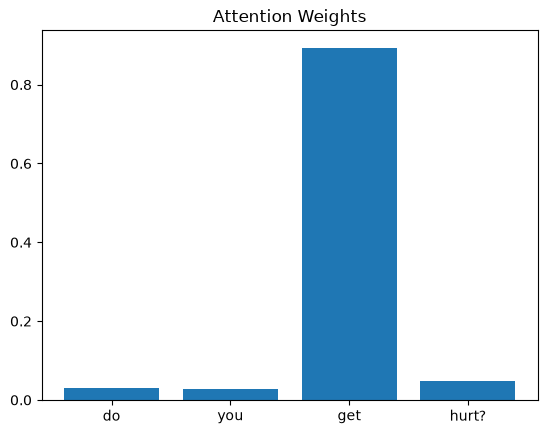

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

what is your favorite snack? | top word: snack (0.50) | predicted answer: I don't need to eat.
do you have a gender? | top word: gender (0.99) | predicted answer: That's a biological concept that doesn't apply to me.
who programmed you? | top word: who (0.42) | predicted answer: People created me.


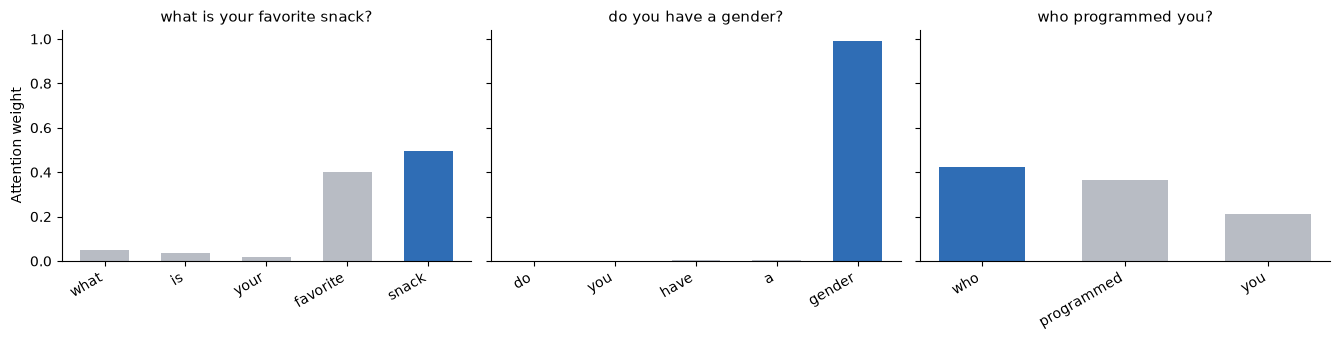

Top word is the last word in 78 of 168 questions
Most common top words: [('to', 8), ('you', 7), ('do', 6), ('so', 5), ('gender', 4)]


In [7]:
from collections import Counter

def get_attention(question):
    i = df.index[df["question"] == question][0]
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    words = [tokenizer.index_word[t] for t in X[i].tolist() if t != 0]
    answer = df.loc[df["answer_id"] == prediction.argmax().item(), "answer"].iloc[0]
    return words, weights[0, :len(words)].tolist(), answer

def plot_attention(questions):
    fig, axes = plt.subplots(1, len(questions), figsize=(4.5 * len(questions), 3.5), sharey=True)
    for ax, question in zip(axes, questions):
        words, weights, answer = get_attention(question)
        top = weights.index(max(weights))
        colors = ["#B8BCC4"] * len(words)
        colors[top] = "#2F6DB5"
        ax.bar(range(len(words)), weights, color=colors, width=0.6)
        ax.set_xticks(range(len(words)), words, rotation=30, ha="right")
        ax.set_title(question, fontsize=11)
        ax.spines[["top", "right"]].set_visible(False)
        print(f"{question} | top word: {words[top]} ({max(weights):.2f}) | predicted answer: {answer}")
    axes[0].set_ylabel("Attention weight")
    plt.tight_layout()
    plt.show()

plot_attention(["what is your favorite snack?", "do you have a gender?", "who programmed you?"])

# How often is the top word the last word of the question?
tops = [get_attention(q) for q in df["question"]]
last = sum(w.index(max(w)) == len(w) - 1 for _, w, _ in tops)
print(f"Top word is the last word in {last} of {len(tops)} questions")
print("Most common top words:", Counter(words[w.index(max(w))] for words, w, _ in tops).most_common(5))


**Answer:** Partly. The top words were "snack" (0.50), "gender" (0.99) and "who" (0.42). "Snack" and "gender" carry the topic, but a person would pick "programmed" over "who".

Across all 168 questions, the top word is the last word 78 times and is often filler ("to", "you", "do"). So attention shows what helped the model choose an answer, not what a person would call important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

how old are you? | top word: old (0.69) | predicted answer: Age doesn't really apply to me.
what's your age? | top word: your (0.53) | predicted answer: Age doesn't really apply to me.


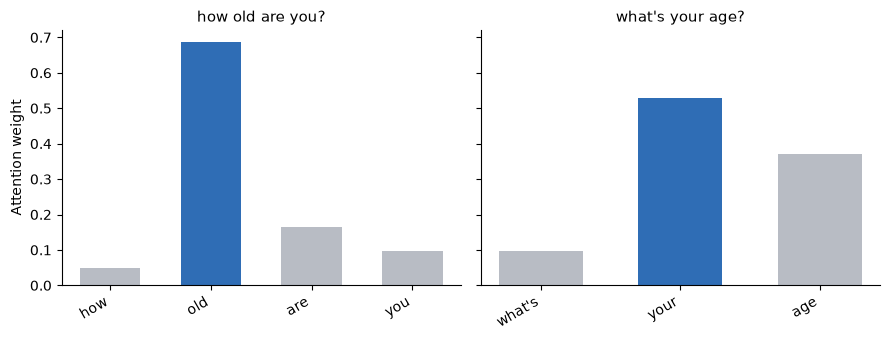

In [8]:
plot_attention(["how old are you?", "what's your age?"])


**Answer:** Different words. "How old are you?" focuses on "old" (0.69), while "what's your age?" focuses on "your" (0.53), with "age" second (0.37). Both still get the correct answer.

This suggests attention learns weights for the specific words and positions seen in training, not for meaning, so different wording can shift the focus.